# 04 · Linear regression

What explains market value, and how well can a simple linear model predict it?

- **Target:** `log_value` (log of market value).
- **Split in time:** train on seasons 2021/22 to 2024/25, test on 2025/26. A player in the test set was never seen in training for that season, which mimics predicting the future.
- **Model A:** age (and age squared), position, height, foot, last season's value.
- **Model B:** Model A plus Premier League performance (minutes, goals per 90, assists per 90).

A and B are compared on the *same* rows, so the difference shows what performance adds.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, modeling

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

df = modeling.prepare(pd.read_csv(config.PROCESSED_DIR / 'player_season.csv'))
TEST_SEASON = config.CURRENT_SEASON

## 1. Which rows go into each model?

- **A, all rows:** every player-season with a previous-season value and complete profile data.
- **A, PL subset / B, PL subset:** only rows with per-90 stats (at least 450 Premier League minutes), so A and B can be compared fairly.

In [2]:
rows_a = modeling.usable_rows(df, modeling.NEEDED_A)
rows_b = modeling.usable_rows(df, modeling.NEEDED_B)

splits = {
    'A (all rows)': (rows_a, modeling.FORMULA_A),
    'A (PL subset)': (rows_b, modeling.FORMULA_A),
    'B (PL subset)': (rows_b, modeling.FORMULA_B),
}
pd.DataFrame(
    {name: [len(modeling.time_split(rows, TEST_SEASON)[0]), len(modeling.time_split(rows, TEST_SEASON)[1])] for name, (rows, _) in splits.items()},
    index=['train rows', 'test rows'],
)

,A (all rows),A (PL subset),B (PL subset)
train rows,1494,746,746
test rows,567,381,381


## 2. Fit the models and score them on the test season

In [3]:
models, scores = {}, {}
for name, (rows, formula) in splits.items():
    train, test = modeling.time_split(rows, TEST_SEASON)
    models[name], scores[name] = modeling.fit_and_score(formula, train, test)

# naive benchmark: predict this season's value = last season's value
train, test = modeling.time_split(rows_b, TEST_SEASON)
scores['Naive: last value (PL subset)'] = modeling.evaluate(test['log_prev_value'], test['log_value'])
train, test = modeling.time_split(rows_a, TEST_SEASON)
scores['Naive: last value (all rows)'] = modeling.evaluate(test['log_prev_value'], test['log_value'])

pd.DataFrame(scores).T.round(3)

,n_test,R2,RMSE (log),median error (EUR M),median error (%)
A (all rows),567.0,0.842,0.627,3.777,33.850
A (PL subset),381.0,0.819,0.448,5.079,29.100
B (PL subset),381.0,0.872,0.376,4.051,21.917
Naive: last value (PL subset),381.0,0.639,0.633,6.000,33.333
Naive: last value (all rows),567.0,0.801,0.704,4.000,36.364


How to read this: **R2** is the share of the variation in log value that the model explains (1 = perfect). **Median error** is how far off a typical prediction is, in millions of euros and in percent.

## 3. What if we drop last season's value?

Last season's value does a lot of the work, but it says little about *why* a player is valuable. Here the same two models are refitted without it:

- **A0:** age, position, height, foot.
- **B0:** A0 plus Premier League performance.

To compare fairly they are scored on the same test players as Model B. A0 and B0 don't need a previous value, so the first season could also be used for training; that made no difference, so the same rows are kept.

In [4]:
compare = {'B (with last value)': scores['B (PL subset)']}
for name, formula in [('B0 (no last value, with performance)', modeling.FORMULA_B0), ('A0 (no last value, no performance)', modeling.FORMULA_A0)]:
    train, test = modeling.time_split(rows_b, TEST_SEASON)
    models[name], compare[name] = modeling.fit_and_score(formula, train, test)
compare['Naive: last value'] = scores['Naive: last value (PL subset)']
pd.DataFrame(compare).T.round(3)

,n_test,R2,RMSE (log),median error (EUR M),median error (%)
B (with last value),381.0,0.872,0.376,4.051,21.917
"B0 (no last value, with performance)",381.0,0.683,0.593,7.043,35.882
"A0 (no last value, no performance)",381.0,0.552,0.706,8.582,40.964
Naive: last value,381.0,0.639,0.633,6.000,33.333


In [5]:
# profile only, all players (no performance, no last value): the weakest setup
rows_a0 = modeling.usable_rows(df, modeling.NEEDED_A0)
train, test = modeling.time_split(rows_a0, TEST_SEASON)
_, s = modeling.fit_and_score(modeling.FORMULA_A0, train, test)
pd.Series(s).round(3)

n_test                  578.000
R2                        0.335
RMSE (log)                1.318
median error (EUR M)      7.942
median error (%)         64.867
dtype: float64

Without last season's value, accuracy drops sharply and the model is no better than the naive guess. Performance still matters: B0 clearly beats A0. Age, position and Premier League output explain roughly two thirds of the variation in value; the rest comes from things this data doesn't have (reputation, contract length, club, transfer demand).

In [6]:
m0 = models['B0 (no last value, with performance)']
pd.DataFrame({'coef': m0.params, 'ci_low': m0.conf_int()[0], 'ci_high': m0.conf_int()[1], 'p_value': m0.pvalues}).round(3)

,coef,ci_low,ci_high,p_value
Intercept,6.047,4.042,8.053,0.000
C(position)[T.Defender],0.215,0.062,0.368,0.006
C(position)[T.Goalkeeper],0.183,-0.035,0.401,0.100
C(position)[T.Midfield],0.233,0.102,0.364,0.000
"C(foot, Treatment('right'))[T.both]",-0.263,-0.681,0.155,0.217
"C(foot, Treatment('right'))[T.left]",0.030,-0.064,0.124,0.534
age,0.703,0.578,0.827,0.000
I(age ** 2),-0.015,-0.017,-0.013,0.000
height_in_cm,0.011,0.004,0.018,0.002
pl_minutes_k,0.328,0.277,0.378,0.000


## 4. What drives value? Model B coefficients

The target is log value, so a coefficient is roughly a proportional change: 0.10 means about +10% value for one more unit of that feature, other things equal.

In [7]:
m = models['B (PL subset)']
coefs = pd.DataFrame({'coef': m.params, 'ci_low': m.conf_int()[0], 'ci_high': m.conf_int()[1], 'p_value': m.pvalues}).round(3)
coefs

,coef,ci_low,ci_high,p_value
Intercept,7.094,5.762,8.427,0.000
C(position)[T.Defender],0.130,0.028,0.231,0.012
C(position)[T.Goalkeeper],0.206,0.062,0.351,0.005
C(position)[T.Midfield],0.155,0.068,0.242,0.000
"C(foot, Treatment('right'))[T.both]",-0.228,-0.505,0.050,0.108
"C(foot, Treatment('right'))[T.left]",0.008,-0.055,0.070,0.812
age,0.081,-0.010,0.173,0.082
I(age ** 2),-0.004,-0.005,-0.002,0.000
height_in_cm,0.006,0.001,0.011,0.012
log_prev_value,0.504,0.471,0.536,0.000


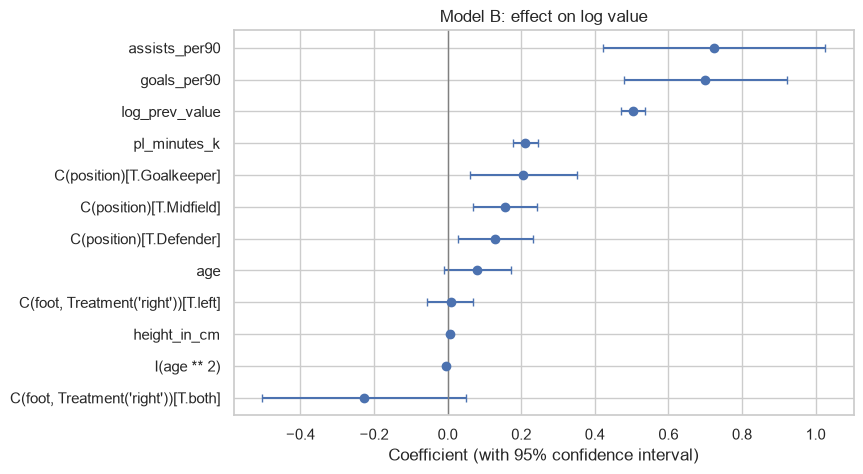

In [8]:
plot = coefs.drop(index='Intercept').sort_values('coef')
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(plot['coef'], plot.index, xerr=[plot['coef'] - plot['ci_low'], plot['ci_high'] - plot['coef']], fmt='o', capsize=3)
ax.axvline(0, color='grey', lw=1)
ax.set(xlabel='Coefficient (with 95% confidence interval)', title='Model B: effect on log value')
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(config.FIGURES_DIR / 'model_b_coefficients.png', dpi=150, bbox_inches='tight')

Features are on different scales (age in years, goals per 90 around 0.1 to 1, last value in log euros), so compare **signs and whether the interval crosses zero**, not the sizes of different features.

In [9]:
# effect of age on value compared with a 25-year-old, holding everything else (including last season's value) fixed
b1, b2 = m.params['age'], m.params['I(age ** 2)']
ages = np.array([20, 22, 25, 28, 30, 33, 36])
effect = np.exp(b1 * (ages - 25) + b2 * (ages ** 2 - 25 ** 2)) - 1
pd.DataFrame({'age': ages, 'value vs a 25-year-old (%)': (effect * 100).round(0)}).set_index('age')

,value vs a 25-year-old (%)
age,
20,48.0
22,29.0
25,0.0
28,-28.0
30,-44.0
33,-63.0
36,-78.0


Because last season's value is in the model, the age terms describe how value *moves* from one season to the next for a given age, not the overall age curve (see the age chart in notebook 03 for that). Older players are marked down more than their previous value alone would suggest.

## 5. Predicted vs actual (test season, Model B)

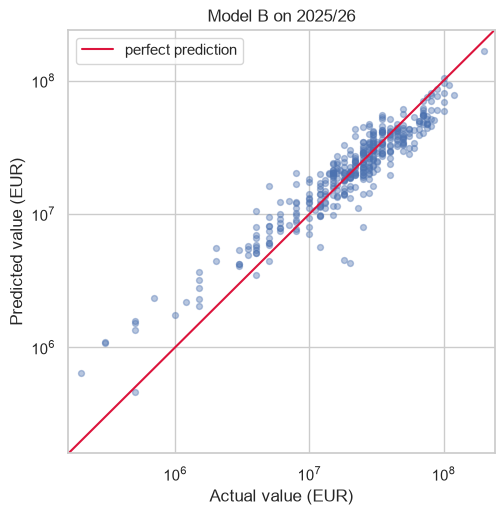

In [10]:
train, test = modeling.time_split(rows_b, TEST_SEASON)
pred = np.expm1(m.predict(test))
actual = np.expm1(test['log_value'])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(actual, pred, alpha=0.4, s=18)
lim = [actual.min() * 0.8, actual.max() * 1.2]
ax.plot(lim, lim, color='crimson', lw=1.5, label='perfect prediction')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set(xlabel='Actual value (EUR)', ylabel='Predicted value (EUR)', title=f'Model B on {TEST_SEASON}/{(TEST_SEASON + 1) % 100}')
ax.legend()
plt.savefig(config.FIGURES_DIR / 'model_b_predicted_vs_actual.png', dpi=150, bbox_inches='tight')

## 6. Biggest misses (test season)

In [11]:
out = test.assign(actual=actual, predicted=pred.round(-4), error_pct=((pred - actual) / actual * 100).round(0))
out['abs_err'] = (out['predicted'] - out['actual']).abs()
out.nlargest(10, 'abs_err')[['name', 'position', 'age', 'current_club', 'actual', 'predicted', 'error_pct']]

,name,position,age,current_club,actual,predicted,error_pct
933,Declan Rice,Midfield,27.383984,Arsenal FC,120000000.0,77940000.0,-35.0
1532,William Saliba,Defender,25.193703,Arsenal FC,100000000.0,58850000.0,-41.0
868,Alexander Isak,Attack,26.699521,Liverpool FC,85000000.0,50210000.0,-41.0
1053,Sandro Tonali,Midfield,26.069815,Newcastle United,80000000.0,45340000.0,-43.0
1172,Erling Haaland,Attack,25.867214,Manchester City,200000000.0,165900000.0,-17.0
1132,Bryan Mbeumo,Attack,26.822724,Manchester United,75000000.0,44130000.0,-41.0
2110,Moisés Caicedo,Midfield,24.583162,Chelsea FC,100000000.0,69530000.0,-30.0
1870,Rayan Cherki,Midfield,22.795346,Manchester City,90000000.0,59730000.0,-34.0
2509,Junior Kroupi,Attack,19.945243,AFC Bournemouth,70000000.0,40780000.0,-42.0
1402,Reece James,Defender,26.485969,Chelsea FC,60000000.0,31360000.0,-48.0


## 7. Caveats

- Last season's value is by far the strongest feature, so the model leans on it. That is a good predictor but a weak explanation of *why* a player is valuable.
- Goals per 90 means different things for strikers and defenders; one shared coefficient averages over positions.
- The biggest misses are all under-predictions of stars: a linear model pulls extreme values towards the average, so it underrates the most valuable players.
- Rows are not independent: the same player appears in several seasons.
- Only players currently in the Premier League are included, so conclusions apply to them, not to all footballers.

## 8. Findings

_To be filled in after we read the results together._